In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest

In [61]:
with fits.open("../data/20261010_taitam/20261010_RT1.fits") as hdul:
    RT1 = Table(hdul[1].data).to_pandas()

print(RT1.shape)
RT1.head()

DIAMETER =                    0  / TELESCOPE diameter                            [astropy.io.fits.card]


(103643, 22)


,JD,Azimuth,Elevation,Az_Offset,El_Offset,Gal_Long,Gal_Lat,LEFT_POL,RIGHT_POL,LEFT_FILT,...,BBC03u,BBC04u,BBC05u,BBC06u,BBC10u,BBC11u,BBC13u,BBC14u,CAL,MARKER
0,2.461324e+06,233.82,45.12,-5.684342e-14,0.0,-102.943812,44.632428,19,39,22,...,25,23,18,15,58,55,39,31,OFF,TPI 000
1,2.461324e+06,233.82,45.12,-5.684342e-14,0.0,-102.943812,44.632428,19,40,22,...,25,23,18,15,58,54,39,31,OFF,TPI 001
2,2.461324e+06,233.82,45.12,-5.684342e-14,0.0,-102.939342,44.635094,19,40,22,...,25,23,18,15,58,55,39,31,OFF,TPI 002
3,2.461324e+06,233.82,45.12,-5.684342e-14,0.0,-102.939342,44.635094,19,40,22,...,25,23,18,15,58,55,39,31,OFF,TPI 003
4,2.461324e+06,233.82,45.12,-5.684342e-14,0.0,-102.939342,44.635094,19,39,22,...,25,23,18,15,58,55,39,31,OFF,TPI 004


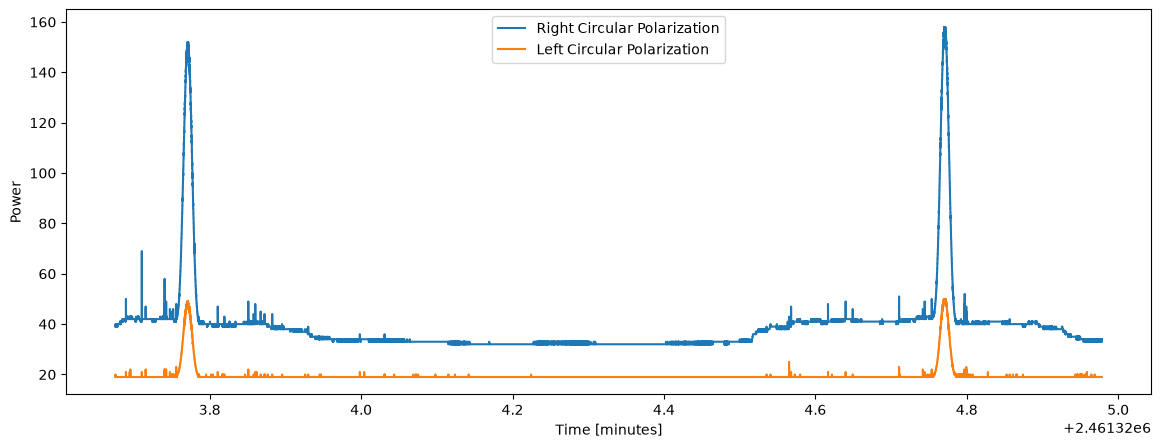

In [62]:
# plot the two polarisations
fig, ax = plt.subplots(
    figsize=(14,5)
)

ax.plot(
    RT1["JD"],
    RT1["RIGHT_POL"],
    label="Right Circular Polarization",
)

ax.plot(
    RT1["JD"],
    RT1["LEFT_POL"],
    label="Left Circular Polarization",
)

ax.set_xlabel("Time [minutes]")
ax.set_ylabel("Power")
ax.legend()

plt.show()

In [69]:
## Normalise
R0 = RT1["RIGHT_POL"].quantile(0.1)
L0 = RT1["LEFT_POL"].quantile(0.1)

Rsig = RT1["RIGHT_POL"] - R0
Lsig = RT1["LEFT_POL"] - L0

THRESHOLD = 10

sun_mask = Rsig > THRESHOLD


gain = (
    Rsig[sun_mask].sum()
    /
    Lsig[sun_mask].sum()
)

Lcorr = gain * Lsig

R = Rsig
L = Lcorr

T = RT1["JD"]

NoSun_mask = Rsig <= THRESHOLD

R_ns = Rsig[NoSun_mask]
L_ns = Lcorr[NoSun_mask]
T_ns = T[NoSun_mask]

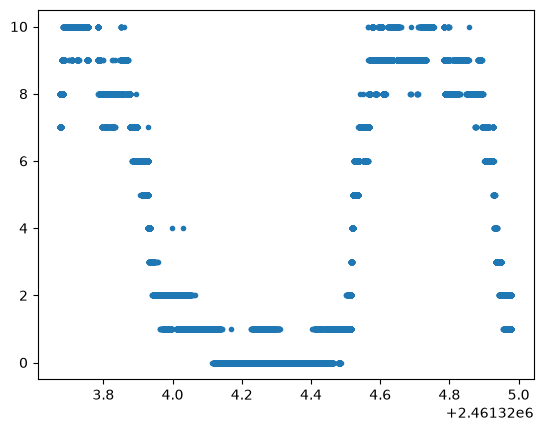

In [70]:
plt.plot(T_ns,R_ns,".")

In [71]:
ASYM = (R-L) / (R+L+1e-6)
ASYM_ns = (R_ns-L_ns) / (R_ns+L_ns+1e-6)

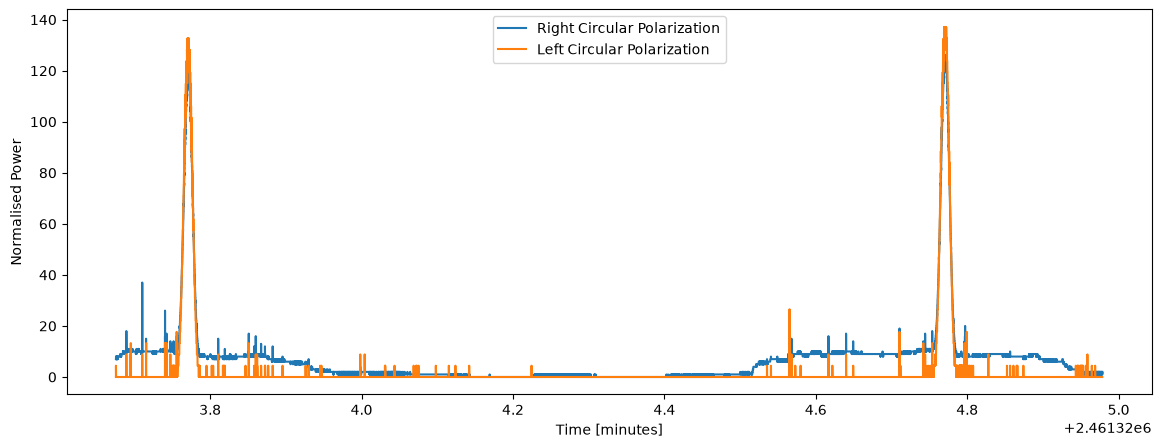

In [72]:
# plot the two polarisations
fig, ax = plt.subplots(
    figsize=(14,5)
)

ax.plot(T,R,label="Right Circular Polarization",)

ax.plot(T,L,label="Left Circular Polarization",)

ax.set_xlabel("Time [minutes]")
ax.set_ylabel("Normalised Power")
ax.legend()

plt.show()

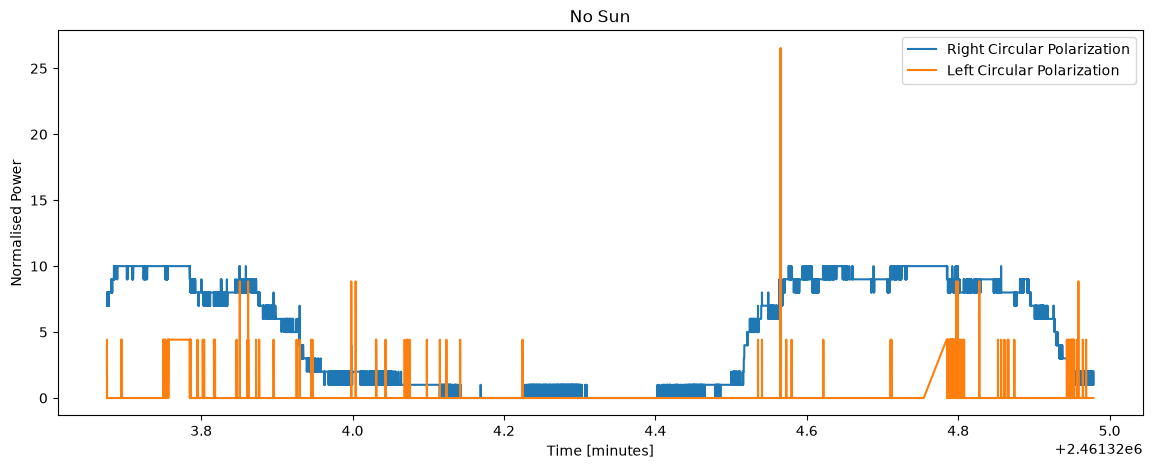

In [73]:
# plot the two polarisations
fig, ax = plt.subplots(
    figsize=(14,5)
)

ax.plot(T_ns,R_ns,label="Right Circular Polarization",)

ax.plot(T_ns,L_ns,label="Left Circular Polarization",)

ax.set_xlabel("Time [minutes]")
ax.set_ylabel("Normalised Power")
ax.legend()
plt.title("No Sun")

plt.show()

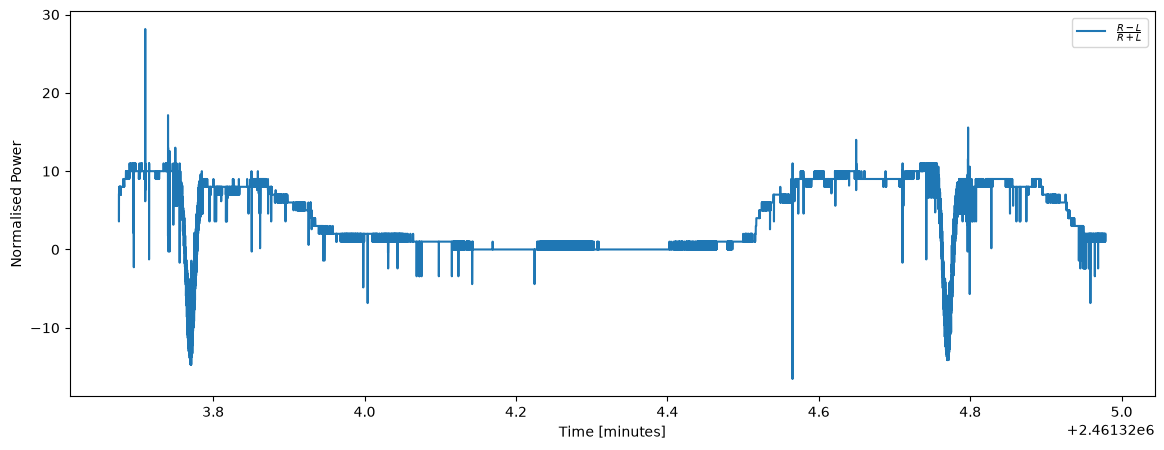

In [74]:
# plot the two polarisations
fig, ax = plt.subplots(
    figsize=(14,5)
)

ax.plot(T,R-L,label=r"$\frac{R-L}{R+L}$",)

ax.set_xlabel("Time [minutes]")
ax.set_ylabel("Normalised Power")
ax.legend()

plt.show()

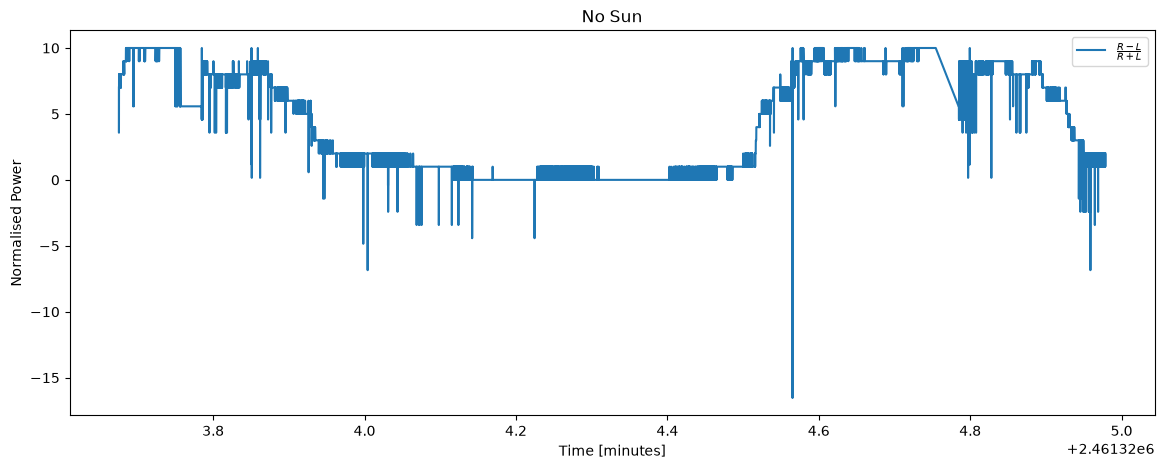

In [75]:
# plot the two polarisations
fig, ax = plt.subplots(
    figsize=(14,5)
)

ax.plot(T_ns,R_ns-L_ns,label=r"$\frac{R-L}{R+L}$",)

ax.set_xlabel("Time [minutes]")
ax.set_ylabel("Normalised Power")
ax.legend()
plt.title("No Sun")

plt.show()

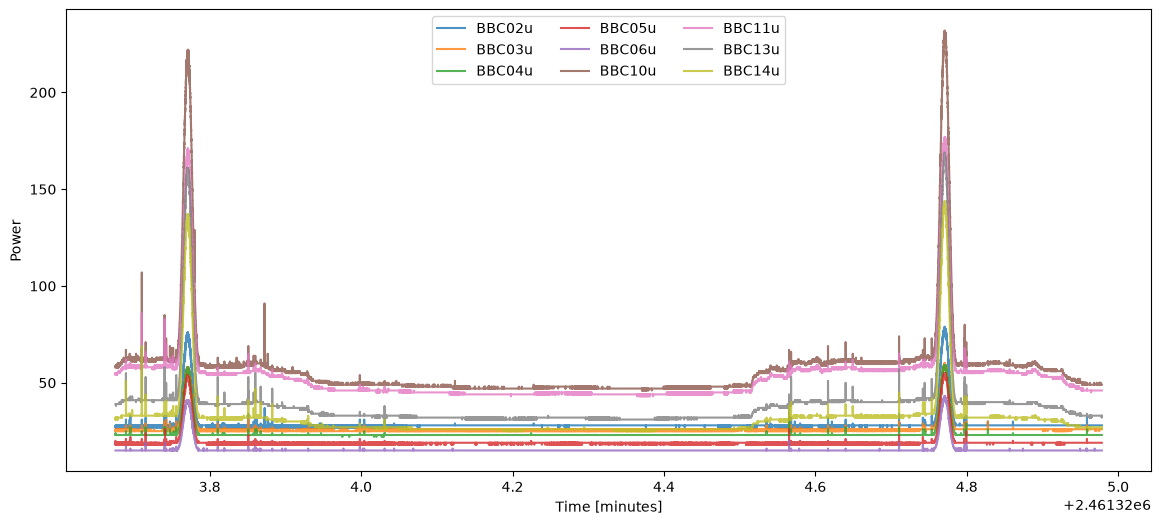

In [76]:
bbc_channels = ["BBC02u","BBC03u","BBC04u","BBC05u","BBC06u","BBC10u","BBC11u","BBC13u","BBC14u"]

fig, ax = plt.subplots(
    figsize=(14,6)
)

for ch in bbc_channels:
    F = RT1[ch]

#    x = (
#        x - x.min()
#    ) / (
#        x.max() - x.min()
#    )

    ax.plot(T,F,alpha=0.8,label=ch)

    ax.set_xlabel("Time [minutes]")
    ax.set_ylabel("Power")

    plt.legend(
    ncol=3)

plt.show()

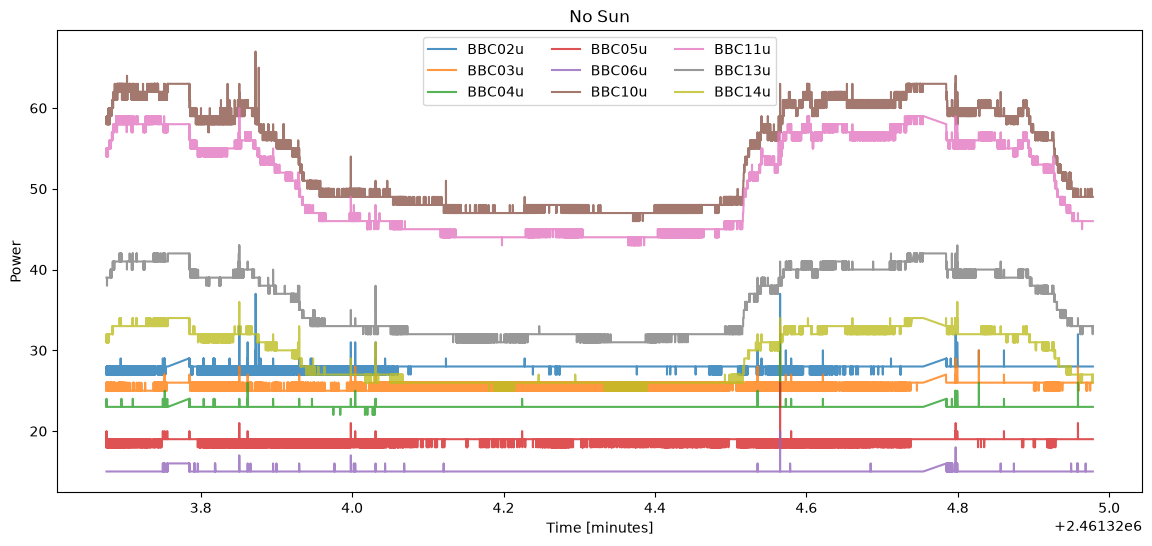

In [77]:
bbc_channels = ["BBC02u","BBC03u","BBC04u","BBC05u","BBC06u","BBC10u","BBC11u","BBC13u","BBC14u"]

fig, ax = plt.subplots(
    figsize=(14,6)
)

for ch in bbc_channels:
    F_ns = RT1[ch][NoSun_mask]

#    x = (
#        x - x.min()
#    ) / (
#        x.max() - x.min()
#    )

    ax.plot(T_ns,F_ns,alpha=0.8,label=ch)

    ax.set_xlabel("Time [minutes]")
    ax.set_ylabel("Power")

    plt.legend(
    ncol=3)
plt.title('No Sun')
plt.show()

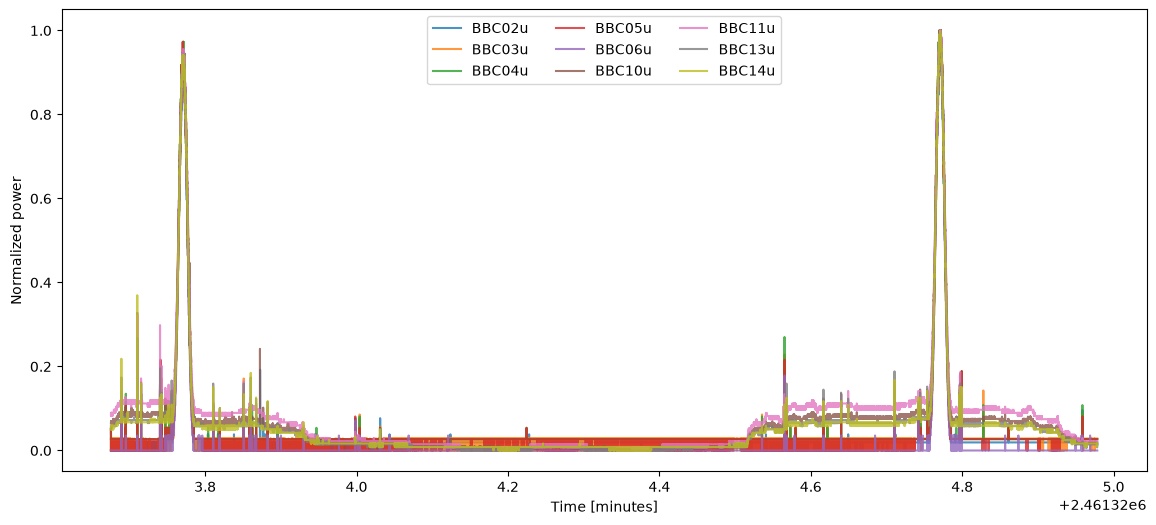

In [78]:
fig, ax = plt.subplots(
    figsize=(14,6)
)

for ch in bbc_channels:
    F = RT1[ch]

    Fn = (
        F - F.min()
    ) / (
        F.max() - F.min()
    )

    ax.plot(T,Fn,alpha=0.8,label=ch)

    ax.set_xlabel("Time [minutes]")
    ax.set_ylabel("Normalized power")

    plt.legend(
    ncol=3)

plt.show()

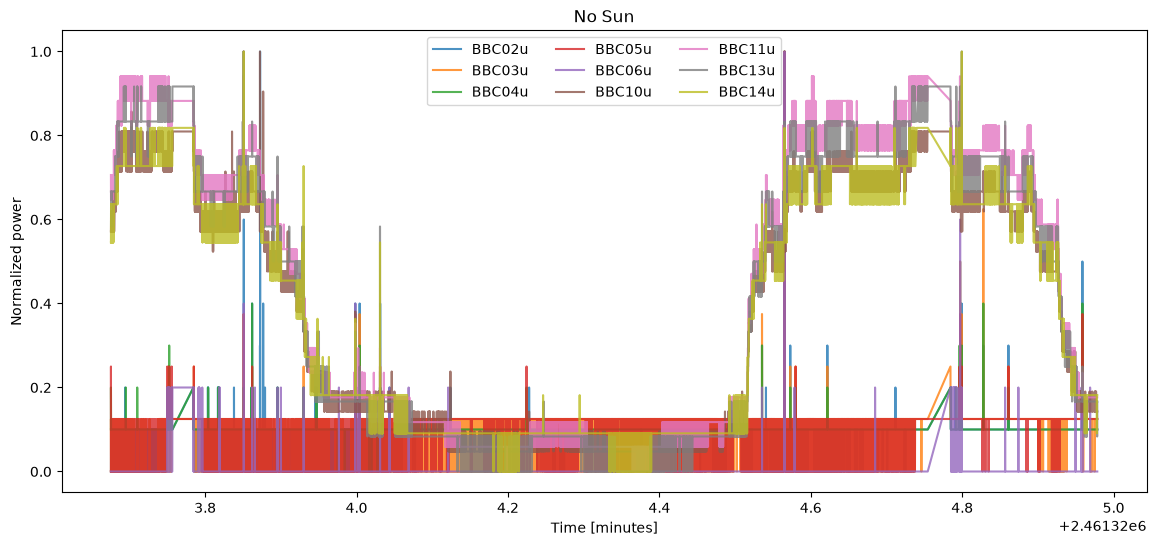

In [79]:
fig, ax = plt.subplots(
    figsize=(14,6)
)

for ch in bbc_channels:
    F_ns = RT1[ch][NoSun_mask]

    Fn_ns = (
        F_ns - F_ns.min()
    ) / (
        F_ns.max() - F_ns.min()
    )

    ax.plot(T_ns,Fn_ns,alpha=0.8,label=ch)

    ax.set_xlabel("Time [minutes]")
    ax.set_ylabel("Normalized power")

    plt.legend(
    ncol=3)
plt.title('No Sun')
plt.show()

Let's try PCA with simple features

In [80]:
features = pd.DataFrame()

features["RIGHT_POL"] = R
features["LEFT_POL"] = L

features["POL_ASYM"] = ASYM

for ch in bbc_channels:
    features[ch] = RT1[ch]

In [81]:
features_ns = pd.DataFrame()

features_ns["RIGHT_POL"] = R_ns
features_ns["LEFT_POL"] = L_ns

features_ns["POL_ASYM"] = ASYM_ns

for ch in bbc_channels:
    features[ch] = RT1[ch][NoSun_mask]

In [82]:
features = features.dropna()
features_ns = features_ns.dropna()

In [83]:
scaler = StandardScaler()
X = scaler.fit_transform(features)

scaler = StandardScaler()
X_ns = scaler.fit_transform(features_ns)


In [88]:
pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(X)

print(
    pca.explained_variance_ratio_
)

[0.47225939 0.20126039]


In [90]:
pca_ns = PCA(
    n_components=2
)

X_pca_ns = pca_ns.fit_transform(X)

print(
    pca.explained_variance_ratio_
)

[0.47225939 0.20126039]


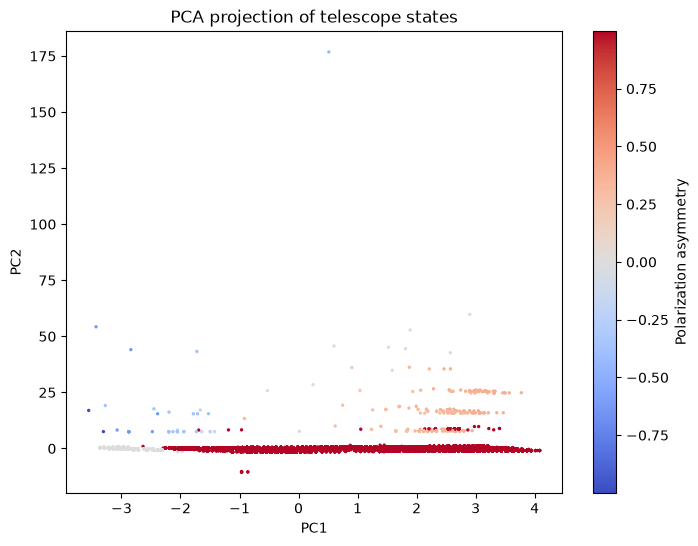

In [89]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    s=2,
    c=features["POL_ASYM"],
    cmap="coolwarm"
)

plt.colorbar(
    label="Polarization asymmetry"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA projection of telescope states"
)

plt.show()

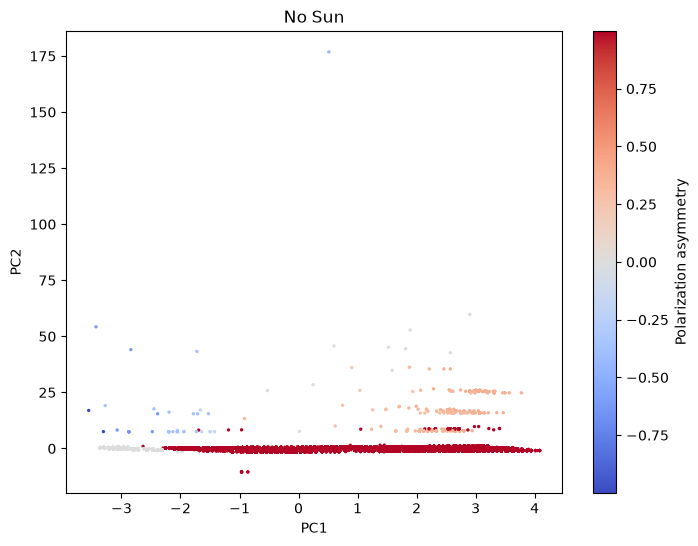

In [91]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca_ns[:,0],
    X_pca_ns[:,1],
    s=2,
    c=features_ns["POL_ASYM"],
    cmap="coolwarm"
)

plt.colorbar(
    label="Polarization asymmetry"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA projection of telescope states"
)

plt.title('No Sun')
plt.show()

ValueError: 'c' argument has 103643 elements, which is inconsistent with 'x' and 'y' with size 95366.

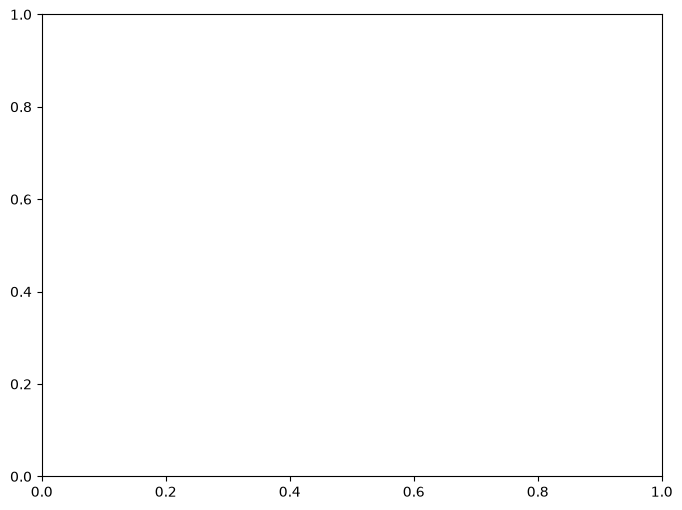

In [92]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    s=2,
    c=T,
    cmap="coolwarm"
)

plt.colorbar(
    label="Time"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA projection of telescope states"
)

plt.show()

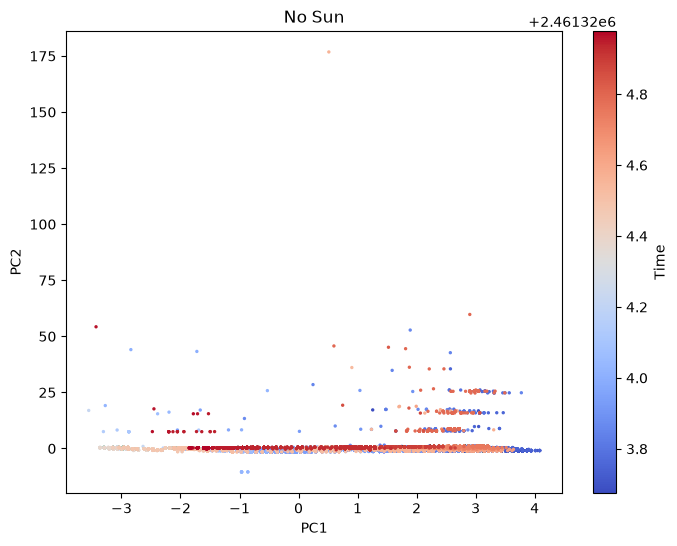

In [93]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca_ns[:,0],
    X_pca_ns[:,1],
    s=2,
    c=T_ns,
    cmap="coolwarm"
)

plt.colorbar(
    label="Time"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA projection of telescope states"
)

plt.title("No Sun")
plt.show()

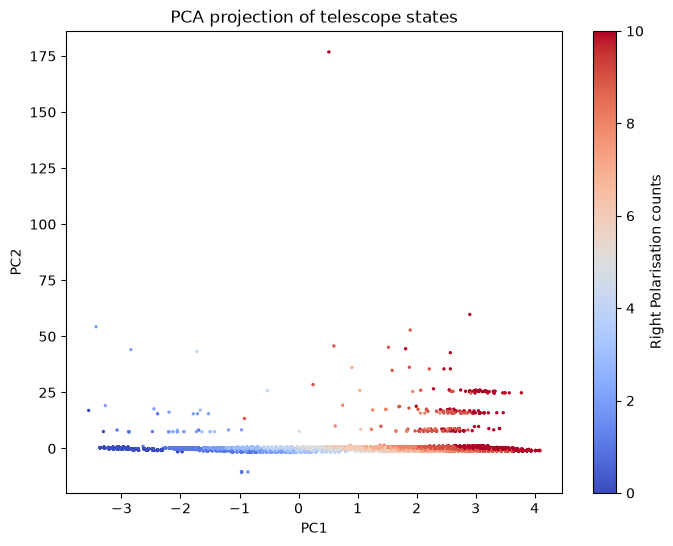

In [94]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    s=2,
    c=features["RIGHT_POL"],
    cmap="coolwarm"
)

plt.colorbar(
    label="Right Polarisation counts"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA projection of telescope states"
)

plt.show()

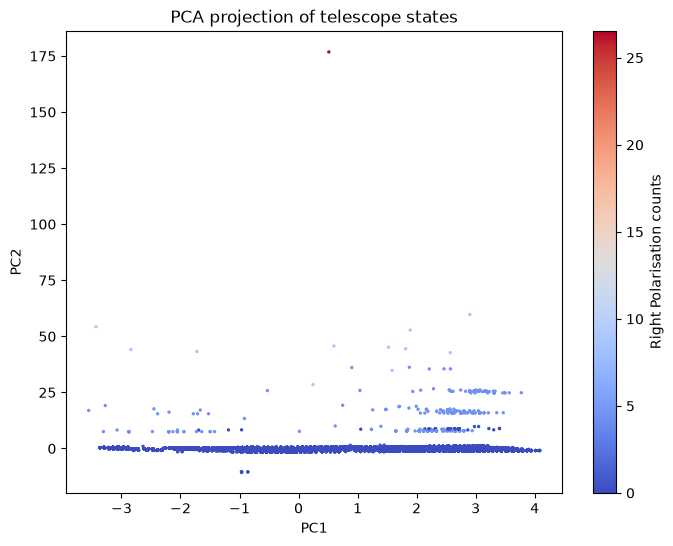

In [95]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    s=2,
    c=features["LEFT_POL"],
    cmap="coolwarm"
)

plt.colorbar(
    label="Right Polarisation counts"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA projection of telescope states"
)

plt.show()

ValueError: 'c' argument has 103643 elements, which is inconsistent with 'x' and 'y' with size 95366.

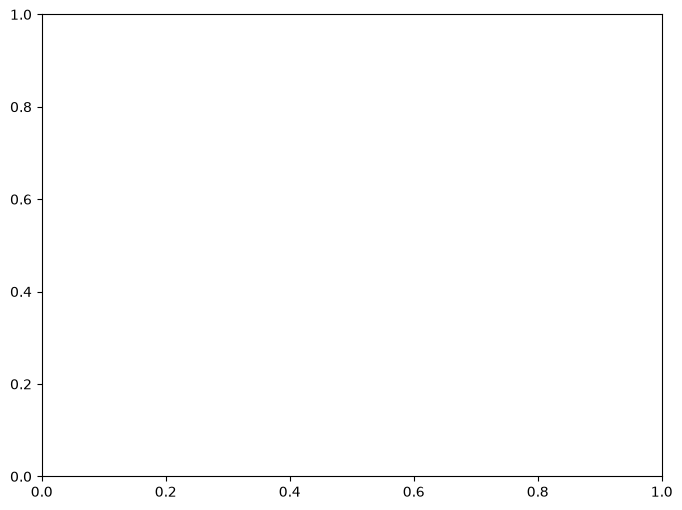

In [96]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    s=2,
    c=R-L,
    cmap="coolwarm"
)

plt.colorbar(
    label="R-L"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA projection of telescope states"
)

plt.show()

ValueError: 'c' argument has 103643 elements, which is inconsistent with 'x' and 'y' with size 95366.

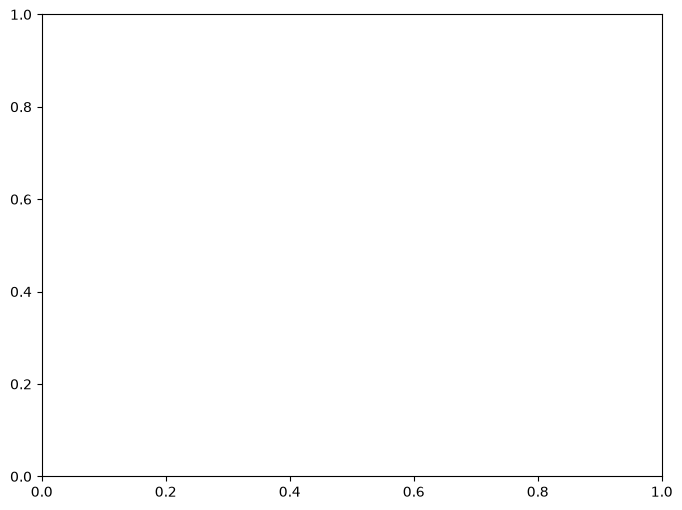

In [97]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    s=2,
    c=R+L,
    cmap="coolwarm"
)

plt.colorbar(
    label="R+L"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA projection of telescope states"
)

plt.show()